# CNN on MNIST Dataset
This notebook demonstrates how to build a Convolutional Neural Network (CNN) to classify images from MNIST dataset

In [1]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

In [2]:
# Load and preprocess the Fashion MNIST dataset
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Normalize the images to a range of 0-1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Reshape images to be compatible with CNN (28x28x1)
train_images = train_images.reshape((train_images.shape[0], 28, 28, 1))
test_images = test_images.reshape((test_images.shape[0], 28, 28, 1))

# One-hot encode the labels
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# Verify the shape of the dataset
train_images.shape, test_images.shape

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


((60000, 28, 28, 1), (10000, 28, 28, 1))

#Build CNN Model
Design a Convolutional Neural Network (CNN) featuring multiple convolutional and max-pooling layers to progressively learn and condense image features. Transform the extracted feature maps into a one-dimensional vector using a flattening layer, then pass them through a dense layer to perform classification. Use a final output layer with 10 neurons to predict the corresponding MNIST clothing category.

In [3]:
# Build the CNN model
model = models.Sequential([
    # First convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten the 3D output to 1D
    layers.Flatten(),

    # Dense (fully connected) layer
    layers.Dense(64, activation='relu'),

    # Output layer with 10 units for 10 classes (Fashion MNIST has 10 classes)
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#Compile and Training
Configure the network using the Adam optimization algorithm and categorical cross-entropy as the loss function, making it suitable for handling multiple output classes. Train the model on the Fashion MNIST training dataset and assess its performance by monitoring validation results on the test dataset throughout the learning process.

In [4]:
# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(train_images, train_labels, epochs=5, batch_size=64, validation_data=(test_images, test_labels))

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 57s 59ms/step - accuracy: 0.8012 - loss: 0.5466 - val_accuracy: 0.8498 - val_loss: 0.4299
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 59ms/step - accuracy: 0.8725 - loss: 0.3512 - val_accuracy: 0.8811 - val_loss: 0.3421
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 58ms/step - accuracy: 0.8893 - loss: 0.3027 - val_accuracy: 0.8795 - val_loss: 0.3388
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 56s 59ms/step - accuracy: 0.9009 - loss: 0.2707 - val_accuracy: 0.8903 - val_loss: 0.3045
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 56s 60ms/step - accuracy: 0.9097 - loss: 0.2470 - val_accuracy: 0.8902 - val_loss: 0.3027


#Evaluate

In [5]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8902 - loss: 0.3027
Test accuracy: 0.8902000188827515


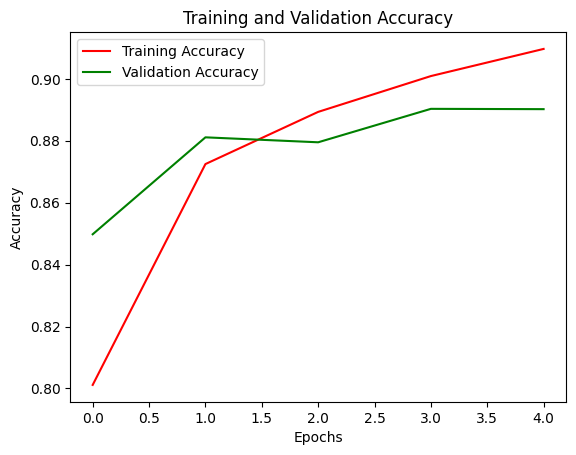

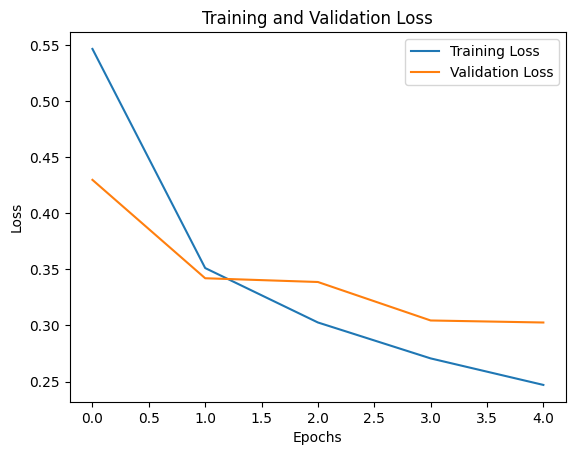

In [7]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy', color = 'red')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color = 'green')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

###  Make Predictions


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


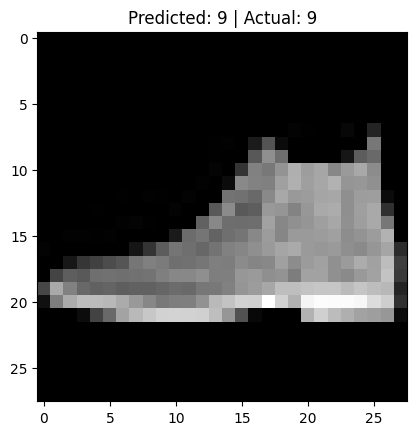

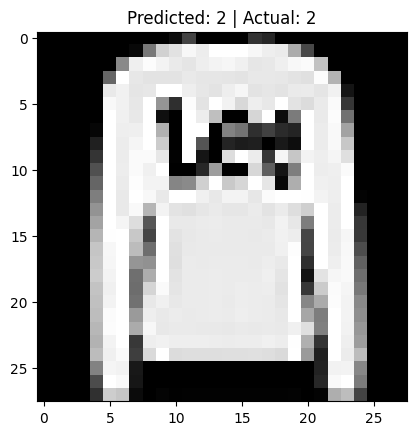

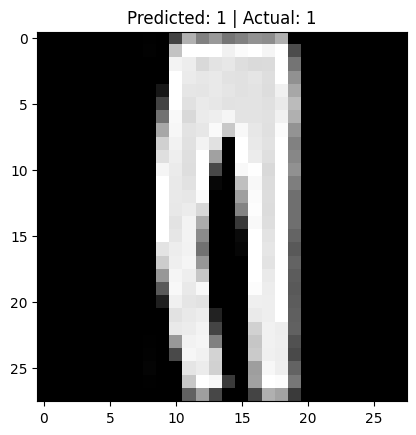

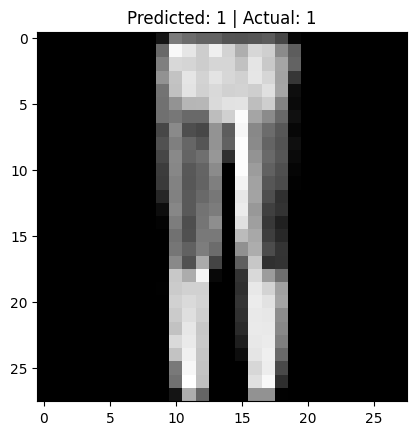

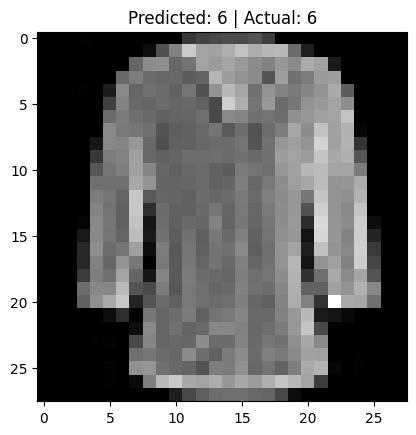

In [8]:
# Make predictions
predictions = model.predict(test_images)

# Display the first 5 test images along with their predicted and actual labels
for i in range(5):
    plt.imshow(test_images[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {predictions[i].argmax()} | Actual: {test_labels[i].argmax()}")
    plt.show()